In [26]:
import pandas as pd
from scipy import stats
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from matplotlib import pyplot as plt
from mlxtend.plotting import plot_confusion_matrix

from keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dropout, Flatten, Dense
from tensorflow.keras.optimizers import Adam

import seaborn as sns

In [3]:
#read dataset into a dataframe
file_path = "anxiety_dataset.csv"

df = pd.read_csv(file_path)


In [4]:
df

,Activity,Ax_p,Ax_w,Ay_p,Ay_w,Az_p,Az_w,GPS1_p,GPS2_p,Gx_p,...,Mx_w,My_p,My_w,Mz_p,Mz_w,PocketDev,Time_p,Time_w,User,WristDev
0,knuckles_cracking,-1.127655,0.77,-2.090134,-0.45,9.476257,-0.34,0.0,0.0,-0.001160,...,-100.98,-45.750427,-58.96,-163.049320,-22.21,S8,1.557220e+12,3392.0,3,SF1
1,knuckles_cracking,-1.127655,0.76,-2.090134,-0.44,9.476257,-0.36,0.0,0.0,-0.003830,...,-100.98,-46.949768,-58.96,-162.150570,-22.21,S8,1.557220e+12,3401.0,3,SF1
2,knuckles_cracking,-1.120483,0.74,-2.075775,-0.43,9.519363,-0.35,0.0,0.0,-0.005508,...,-100.98,-46.800232,-58.96,-161.549380,-22.21,S8,1.557220e+12,3420.0,3,SF1
3,knuckles_cracking,-1.113296,0.74,-2.061401,-0.40,9.533722,-0.38,0.0,0.0,-0.005493,...,-100.98,-46.949768,-58.96,-162.150570,-22.21,S8,1.557220e+12,3440.0,3,SF1
4,knuckles_cracking,-1.120483,0.74,-2.047043,-0.43,9.526535,-0.39,0.0,0.0,-0.005798,...,-100.68,-46.800232,-59.41,-164.549260,-19.20,S8,1.557220e+12,3460.0,3,SF1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.086960,0.23,0.784858,0.22,9.869260,-0.75,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,125969.0,6,SF1
709578,hand_scratching,0.086960,0.18,0.784858,0.42,9.869260,-0.72,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,125989.0,6,SF1
709579,hand_scratching,0.086960,0.13,0.784858,0.43,9.869260,-0.76,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,126010.0,6,SF1
709580,hand_scratching,0.086960,0.12,0.784858,0.32,9.869260,-0.78,0.0,0.0,-0.000206,...,-66.47,-33.377078,-11.10,-21.132091,-43.06,SJ7,1.570370e+12,126030.0,6,SF1


In [4]:
df.apply(lambda s: pd.to_numeric(s, errors='coerce').notnull().all())

Activity     False
Ax_p          True
Ax_w          True
Ay_p          True
Ay_w          True
Az_p          True
Az_w          True
GPS1_p       False
GPS2_p       False
Gx_p          True
Gx_w          True
Gy_p          True
Gy_w          True
Gz_p          True
Gz_w          True
Mx_p          True
Mx_w          True
My_p          True
My_w          True
Mz_p          True
Mz_w          True
PocketDev    False
Time_p        True
Time_w        True
User          True
WristDev     False
dtype: bool

## Separate Dataset into pocket and wrist data

In [5]:
import numpy as np
import tensorflow as tf
import seaborn as sns
colunn_names = ["Activity", "Ax_p", "Ax_w", "Ay_p", "Ay_w", "Az_p", "Az_w", "GPS1_p","GPS2_p",  "Gx_p", "Gx_w", "Gy_p", "Gy_w", "Gz_p", "Gz_w",  "Mx_p", "Mx_w", "My_p", "My_w", "Mz_p", "Mz_w","PocketDev","Time_p", "Time_w", "User", "WristDev"]


In [6]:
df_w = df.drop(["Ax_p", "Ay_p", "Az_p", "GPS1_p","GPS2_p", "Gx_p", "Gy_p", "Gz_p",  "Mx_p", "My_p", "Mz_p","PocketDev", "Time_p","WristDev" ], axis =1)
df_w #dataset for waist data

,Activity,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,Mx_w,My_w,Mz_w,Time_w,User
0,knuckles_cracking,0.77,-0.45,-0.34,-4.70,-0.98,2.44,-100.98,-58.96,-22.21,3392.0,3
1,knuckles_cracking,0.76,-0.44,-0.36,-8.48,-4.39,5.24,-100.98,-58.96,-22.21,3401.0,3
2,knuckles_cracking,0.74,-0.43,-0.35,-15.49,-9.15,6.59,-100.98,-58.96,-22.21,3420.0,3
3,knuckles_cracking,0.74,-0.40,-0.38,-20.12,-14.27,6.71,-100.98,-58.96,-22.21,3440.0,3
4,knuckles_cracking,0.74,-0.43,-0.39,-14.02,-19.94,7.13,-100.68,-59.41,-19.20,3460.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.23,0.22,-0.75,-163.54,-3.23,37.87,-66.47,-11.10,-43.06,125969.0,6
709578,hand_scratching,0.18,0.42,-0.72,-231.59,-17.87,31.16,-66.47,-11.10,-43.06,125989.0,6
709579,hand_scratching,0.13,0.43,-0.76,-248.54,-24.94,13.60,-66.47,-11.10,-43.06,126010.0,6
709580,hand_scratching,0.12,0.32,-0.78,-262.13,-27.56,-2.26,-66.47,-11.10,-43.06,126030.0,6


In [15]:
df_p = df.drop(["Ax_w", "Ay_w", "Az_w", "GPS1_p","GPS2_p", "Gx_w", "Gy_w", "Gz_w",  "Mx_w", "My_w", "Mz_w","PocketDev", "Time_w","WristDev" ], axis = 1)
df_p #dataset for pocket

,Activity,Ax_p,Ay_p,Az_p,Gx_p,Gy_p,Gz_p,Mx_p,My_p,Mz_p,Time_p,User
0,knuckles_cracking,-1.127655,-2.090134,9.476257,-0.001160,0.003464,0.014908,21.600342,-45.750427,-163.049320,1.557220e+12,3
1,knuckles_cracking,-1.127655,-2.090134,9.476257,-0.003830,0.006256,0.022598,21.449280,-46.949768,-162.150570,1.557220e+12,3
2,knuckles_cracking,-1.120483,-2.075775,9.519363,-0.005508,0.009537,0.032104,21.899414,-46.800232,-161.549380,1.557220e+12,3
3,knuckles_cracking,-1.113296,-2.061401,9.533722,-0.005493,0.011307,0.036667,21.000671,-46.949768,-162.150570,1.557220e+12,3
4,knuckles_cracking,-1.120483,-2.047043,9.526535,-0.005798,0.011841,0.037384,20.849610,-46.800232,-164.549260,1.557220e+12,3
...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.086960,0.784858,9.869260,-0.000206,-0.000446,-0.001444,-1.012981,-33.377078,-21.132091,1.570370e+12,6
709578,hand_scratching,0.086960,0.784858,9.869260,-0.000206,-0.000446,-0.001444,-1.012981,-33.377078,-21.132091,1.570370e+12,6
709579,hand_scratching,0.086960,0.784858,9.869260,-0.000206,-0.000446,-0.001444,-1.012981,-33.377078,-21.132091,1.570370e+12,6
709580,hand_scratching,0.086960,0.784858,9.869260,-0.000206,-0.000446,-0.001444,-1.012981,-33.377078,-21.132091,1.570370e+12,6


In [13]:
df_w = df.drop(["Ax_p", "Ay_p", "Az_p", "GPS1_p","GPS2_p", "Gx_p", "Gy_p", "Gz_p",  "Mx_p", "My_p", "Mz_p","PocketDev", "Time_p","WristDev" ], axis = 1)
df_w #dataset for waist

,Activity,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,Mx_w,My_w,Mz_w,Time_w,User
0,knuckles_cracking,0.77,-0.45,-0.34,-4.70,-0.98,2.44,-100.98,-58.96,-22.21,3392.0,3
1,knuckles_cracking,0.76,-0.44,-0.36,-8.48,-4.39,5.24,-100.98,-58.96,-22.21,3401.0,3
2,knuckles_cracking,0.74,-0.43,-0.35,-15.49,-9.15,6.59,-100.98,-58.96,-22.21,3420.0,3
3,knuckles_cracking,0.74,-0.40,-0.38,-20.12,-14.27,6.71,-100.98,-58.96,-22.21,3440.0,3
4,knuckles_cracking,0.74,-0.43,-0.39,-14.02,-19.94,7.13,-100.68,-59.41,-19.20,3460.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.23,0.22,-0.75,-163.54,-3.23,37.87,-66.47,-11.10,-43.06,125969.0,6
709578,hand_scratching,0.18,0.42,-0.72,-231.59,-17.87,31.16,-66.47,-11.10,-43.06,125989.0,6
709579,hand_scratching,0.13,0.43,-0.76,-248.54,-24.94,13.60,-66.47,-11.10,-43.06,126010.0,6
709580,hand_scratching,0.12,0.32,-0.78,-262.13,-27.56,-2.26,-66.47,-11.10,-43.06,126030.0,6


In [16]:
df_p.shape
df_w.shape
df.shape

(709582, 26)

In [ ]:
#Using leave-one-out technique and using user 10 as the test 
dfw_test = df_w[df_w["User"]== 10]
dfw_train = df_w[df_w["User"]!= 10]
dfw_test.shape

(69274, 12)

In [ ]:
dfw_train.shape

(640308, 12)

In [ ]:
#Using leave-one-out technique and using user 2 as the test
dfp_test = df_p[df_p["User"]== 2]
dfp_train = df_p[df_p["User"]!= 2]

# Check if data is balanced

<Axes: xlabel='Activity', ylabel='count'>

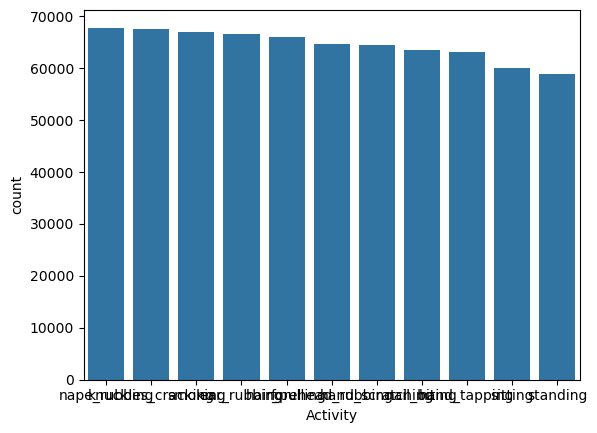

In [7]:
#check the distribution of the activities
sns.countplot(x='Activity', data = df, order=df.Activity.value_counts().index)

<Axes: xlabel='User', ylabel='count'>

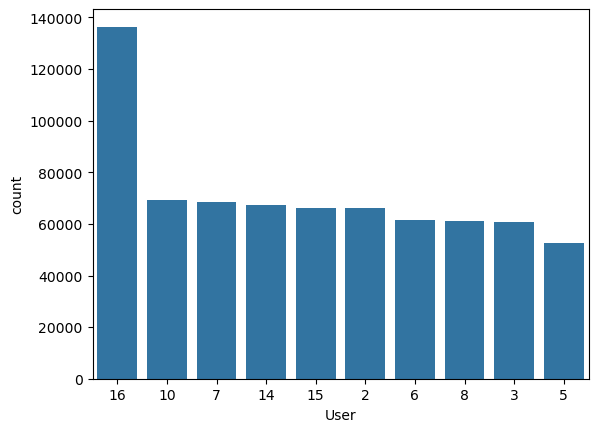

In [8]:
#Check the distribution for users
sns.countplot(x='User', data = df, order=df.User.value_counts().index)

In [9]:
def plot_activity(activity,df,axes):
    """
    Function that plots the x,y and z signals of a single activity 
    """
    data =df[df['Activity']==activity][axes][:200]
    axis = data.plot(subplots=True, figsize=(16,12), title=activity)
    for ax in axis:
        ax.legend(loc='lower left', bbox_to_anchor=(1.0, 0.5))

In [10]:
#lists containing the axes for a, g and m for pocket and wrist data
aw_axis = ["Ax_w", "Ay_w", "Az_w"]
gw_axis = ["Gx_w", "Gy_w", "Gz_w"]
mw_axis = ["Mx_w", "My_w", "Mz_w"]
ap_axis = ["Ax_p", "Ay_p", "Az_p"]
gp_axis = ["Gx_p", "Gy_p", "Gz_p"]
mp_axis = ["Mx_p", "My_p", "Mz_p"]

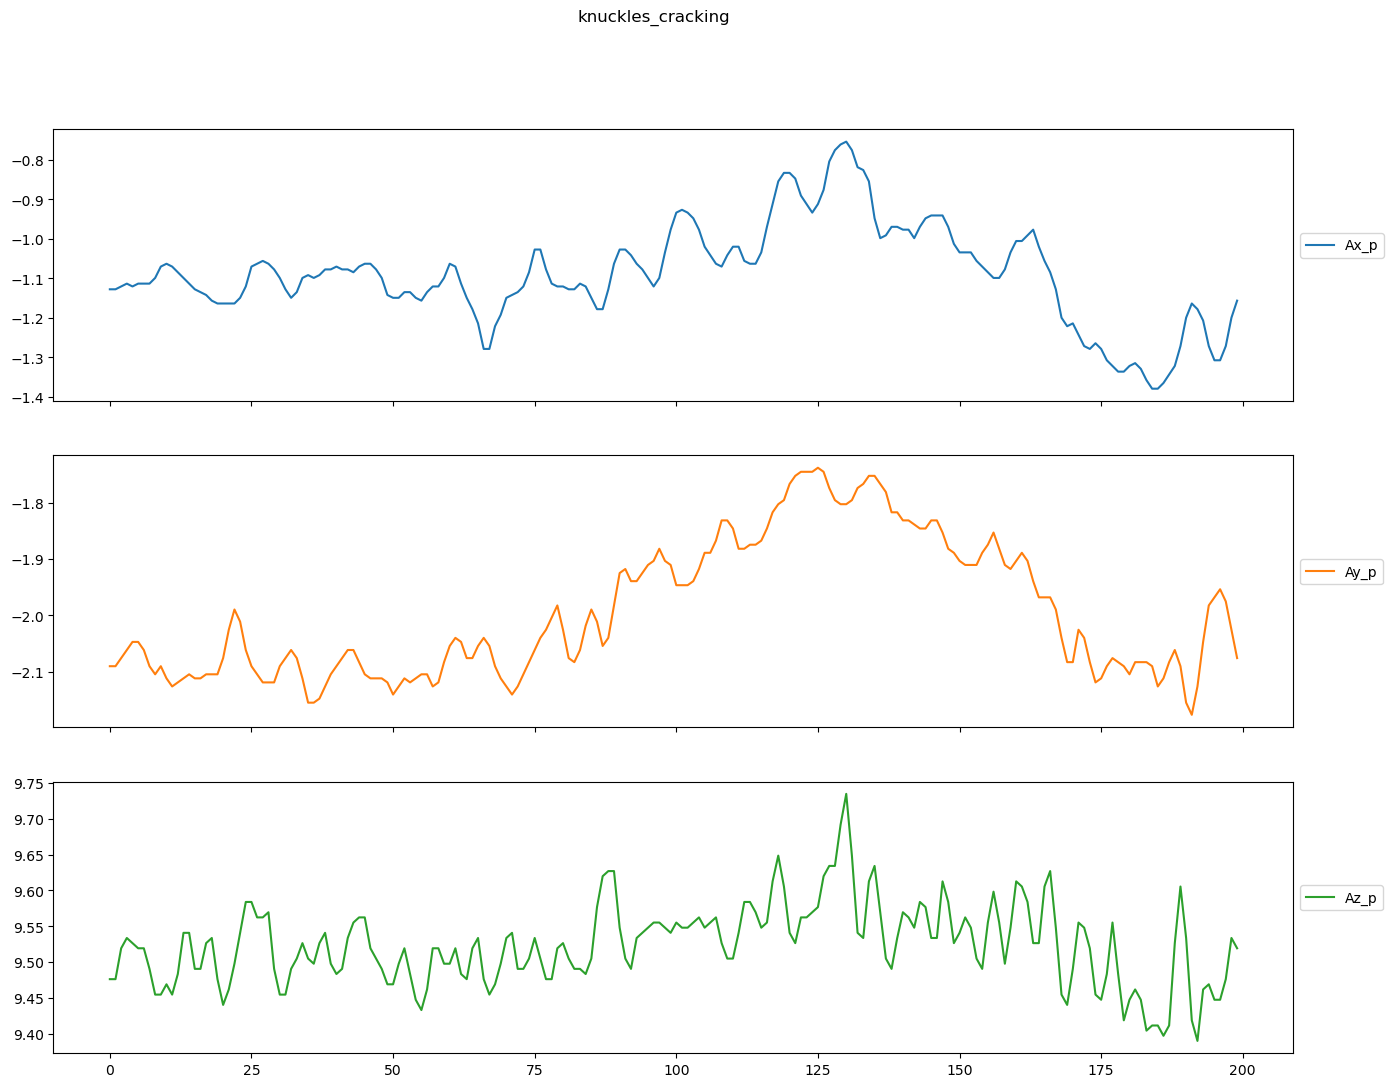

In [11]:
plot_activity("knuckles_cracking",df,ap_axis)

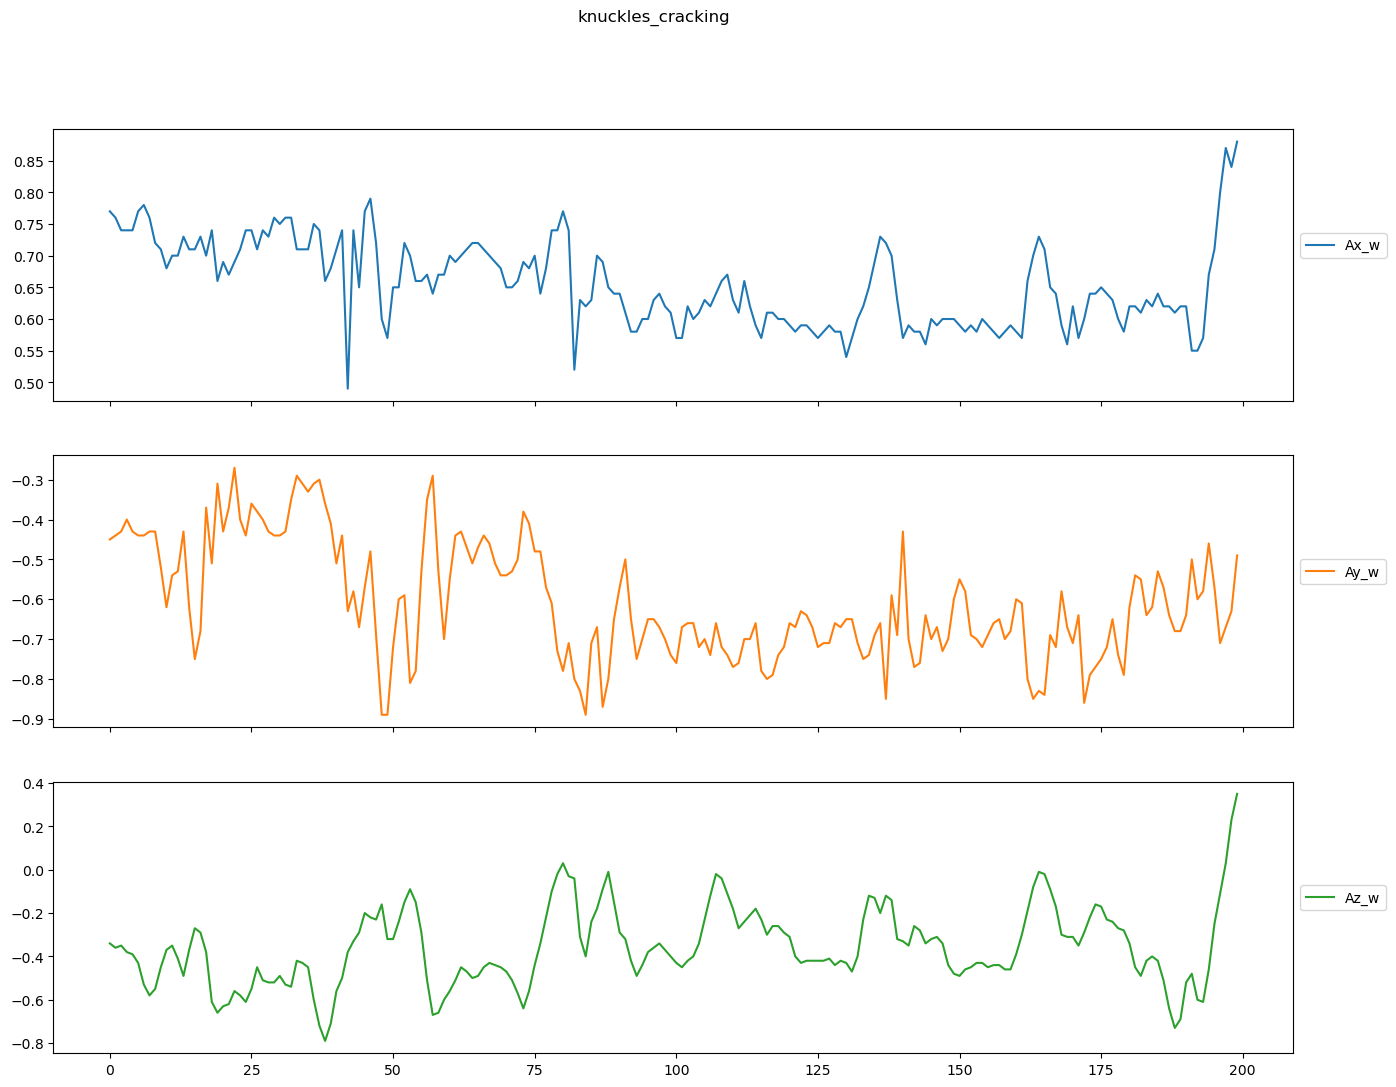

In [12]:
plot_activity("knuckles_cracking",df,aw_axis)

In [14]:
df['Activity'].value_counts()

Activity
nape_rubbing         67859
knuckles_cracking    67498
smoking              66937
ear_rubbing          66599
hair_pulling         65973
forehead_rubbing     64604
hand_scratching      64490
nail_biting          63457
hand_tapping         63220
sitting              59996
standing             58949
Name: count, dtype: int64

In [15]:
srate = 50

In [16]:
df_all = df.drop(["GPS1_p","GPS2_p",'User',"PocketDev", "Time_p","Time_w", "WristDev" ], axis = 1)
df_all #dataset for wrist and pocket

,Activity,Ax_p,Ax_w,Ay_p,Ay_w,Az_p,Az_w,Gx_p,Gx_w,Gy_p,Gy_w,Gz_p,Gz_w,Mx_p,Mx_w,My_p,My_w,Mz_p,Mz_w
0,knuckles_cracking,-1.127655,0.77,-2.090134,-0.45,9.476257,-0.34,-0.001160,-4.70,0.003464,-0.98,0.014908,2.44,21.600342,-100.98,-45.750427,-58.96,-163.049320,-22.21
1,knuckles_cracking,-1.127655,0.76,-2.090134,-0.44,9.476257,-0.36,-0.003830,-8.48,0.006256,-4.39,0.022598,5.24,21.449280,-100.98,-46.949768,-58.96,-162.150570,-22.21
2,knuckles_cracking,-1.120483,0.74,-2.075775,-0.43,9.519363,-0.35,-0.005508,-15.49,0.009537,-9.15,0.032104,6.59,21.899414,-100.98,-46.800232,-58.96,-161.549380,-22.21
3,knuckles_cracking,-1.113296,0.74,-2.061401,-0.40,9.533722,-0.38,-0.005493,-20.12,0.011307,-14.27,0.036667,6.71,21.000671,-100.98,-46.949768,-58.96,-162.150570,-22.21
4,knuckles_cracking,-1.120483,0.74,-2.047043,-0.43,9.526535,-0.39,-0.005798,-14.02,0.011841,-19.94,0.037384,7.13,20.849610,-100.68,-46.800232,-59.41,-164.549260,-19.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
709577,hand_scratching,0.086960,0.23,0.784858,0.22,9.869260,-0.75,-0.000206,-163.54,-0.000446,-3.23,-0.001444,37.87,-1.012981,-66.47,-33.377078,-11.10,-21.132091,-43.06
709578,hand_scratching,0.086960,0.18,0.784858,0.42,9.869260,-0.72,-0.000206,-231.59,-0.000446,-17.87,-0.001444,31.16,-1.012981,-66.47,-33.377078,-11.10,-21.132091,-43.06
709579,hand_scratching,0.086960,0.13,0.784858,0.43,9.869260,-0.76,-0.000206,-248.54,-0.000446,-24.94,-0.001444,13.60,-1.012981,-66.47,-33.377078,-11.10,-21.132091,-43.06
709580,hand_scratching,0.086960,0.12,0.784858,0.32,9.869260,-0.78,-0.000206,-262.13,-0.000446,-27.56,-0.001444,-2.26,-1.012981,-66.47,-33.377078,-11.10,-21.132091,-43.06


## Encode Data

In [17]:
#encode data
label = LabelEncoder()
df_all['label'] = label.fit_transform(df_all['Activity'])
df_all.head()

,Activity,Ax_p,Ax_w,Ay_p,Ay_w,Az_p,Az_w,Gx_p,Gx_w,Gy_p,Gy_w,Gz_p,Gz_w,Mx_p,Mx_w,My_p,My_w,Mz_p,Mz_w,label
0,knuckles_cracking,-1.127655,0.77,-2.090134,-0.45,9.476257,-0.34,-0.001160,-4.70,0.003464,-0.98,0.014908,2.44,21.600342,-100.98,-45.750427,-58.96,-163.04932,-22.21,5
1,knuckles_cracking,-1.127655,0.76,-2.090134,-0.44,9.476257,-0.36,-0.003830,-8.48,0.006256,-4.39,0.022598,5.24,21.449280,-100.98,-46.949768,-58.96,-162.15057,-22.21,5
2,knuckles_cracking,-1.120483,0.74,-2.075775,-0.43,9.519363,-0.35,-0.005508,-15.49,0.009537,-9.15,0.032104,6.59,21.899414,-100.98,-46.800232,-58.96,-161.54938,-22.21,5
3,knuckles_cracking,-1.113296,0.74,-2.061401,-0.40,9.533722,-0.38,-0.005493,-20.12,0.011307,-14.27,0.036667,6.71,21.000671,-100.98,-46.949768,-58.96,-162.15057,-22.21,5
4,knuckles_cracking,-1.120483,0.74,-2.047043,-0.43,9.526535,-0.39,-0.005798,-14.02,0.011841,-19.94,0.037384,7.13,20.849610,-100.68,-46.800232,-59.41,-164.54926,-19.20,5


In [18]:
label.classes_

array(['ear_rubbing', 'forehead_rubbing', 'hair_pulling',
       'hand_scratching', 'hand_tapping', 'knuckles_cracking',
       'nail_biting', 'nape_rubbing', 'sitting', 'smoking', 'standing'],
      dtype=object)

## Standardize Data

In [19]:
#standardize data
columns = ["Ax_w", "Ay_w", "Az_w","Gx_w", "Gy_w", "Gz_w","Mx_w", "My_w", "Mz_w","Ax_p", "Ay_p", "Az_p","Gx_p", "Gy_p", "Gz_p","Mx_p", "My_p", "Mz_p"]
x=df_all[columns]
scaler = StandardScaler()
x = scaler.fit_transform(x)
scaled_x = pd.DataFrame(data = x, columns = columns)

y = df_all['label']

scaled_x['label'] = y.values

scaled_x

,Ax_w,Ay_w,Az_w,Gx_w,Gy_w,Gz_w,Mx_w,My_w,Mz_w,Ax_p,Ay_p,Az_p,Gx_p,Gy_p,Gz_p,Mx_p,My_p,Mz_p,label
0,0.936100,-1.018411,0.301650,-0.078197,-0.114346,0.112631,-0.376133,-1.342065,0.054431,-0.825472,-0.768186,0.401639,0.004800,0.000889,0.073656,0.169149,-1.467406,-4.531155,5
1,0.918868,-0.998366,0.250270,-0.156196,-0.258315,0.246124,-0.376133,-1.342065,0.054431,-0.825472,-0.768186,0.401639,-0.001736,0.006133,0.101261,0.164267,-1.502154,-4.500995,5
2,0.884404,-0.978321,0.275960,-0.300845,-0.459281,0.310486,-0.376133,-1.342065,0.054431,-0.819490,-0.764569,0.413551,-0.005844,0.012295,0.135385,0.178816,-1.497821,-4.480821,5
3,0.884404,-0.918187,0.198890,-0.396383,-0.675446,0.316207,-0.376133,-1.342065,0.054431,-0.813496,-0.760947,0.417519,-0.005806,0.015619,0.151762,0.149766,-1.502154,-4.500995,5
4,0.884404,-0.978321,0.173200,-0.270512,-0.914831,0.336231,-0.365075,-1.358917,0.193868,-0.819490,-0.757330,0.415533,-0.006553,0.016622,0.154336,0.144884,-1.497821,-4.581490,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
709577,0.005570,0.324587,-0.751639,-3.355805,-0.209340,1.801788,0.895933,0.450215,-0.911432,0.187570,-0.043883,0.510243,0.007134,-0.006455,0.014961,-0.561770,-1.108928,0.231280,3
709578,-0.080590,0.725482,-0.674569,-4.759993,-0.827437,1.481883,0.895933,0.450215,-0.911432,0.187570,-0.043883,0.510243,0.007134,-0.006455,0.014961,-0.561770,-1.108928,0.231280,3
709579,-0.166750,0.745527,-0.777329,-5.109750,-1.125930,0.644694,0.895933,0.450215,-0.911432,0.187570,-0.043883,0.510243,0.007134,-0.006455,0.014961,-0.561770,-1.108928,0.231280,3
709580,-0.183982,0.525034,-0.828709,-5.390175,-1.236546,-0.111446,0.895933,0.450215,-0.911432,0.187570,-0.043883,0.510243,0.007134,-0.006455,0.014961,-0.561770,-1.108928,0.231280,3


In [20]:
#window frame
window_size = 200
slide_size = 100

In [27]:
def get_window(df, window_size, slide_size):
    N_features = 18
    
    windows = []
    labels = []
    for i in range(0, len(df)-window_size, slide_size):
        Ax_w = df['Ax_w'].values[i: i + window_size]
        Ay_w = df['Ay_w'].values[i: i + window_size]
        Az_w = df['Az_w'].values[i: i + window_size]
        Ax_p = df['Ax_p'].values[i: i + window_size]
        Ay_p = df['Ay_p'].values[i: i + window_size]
        Az_p = df['Az_p'].values[i: i + window_size]
        Gx_w = df['Gx_w'].values[i: i + window_size]
        Gy_w = df['Gy_w'].values[i: i + window_size]
        Gz_w = df['Gz_w'].values[i: i + window_size]
        Gx_p = df['Gx_p'].values[i: i + window_size]
        Gy_p = df['Gy_p'].values[i: i + window_size]
        Gz_p = df['Gz_p'].values[i: i + window_size]
        Mx_w = df['Mx_w'].values[i: i + window_size]
        My_w = df['My_w'].values[i: i + window_size]
        Mz_w = df['Mz_w'].values[i: i + window_size]
        Mx_p = df['Mx_p'].values[i: i + window_size]
        My_p = df['My_p'].values[i: i + window_size]
        Mz_p = df['Mz_p'].values[i: i + window_size]
        
        label = stats.mode(df['label'][i:i+window_size])[0]
        windows.append([Ax_w ,Ay_w ,Az_w,Ax_p,Ay_p, Az_p ,Gx_w ,Gy_w ,Gz_w ,Gx_p,Gy_p ,Gz_p ,Mx_w , My_w , Mz_w , Mx_p , My_p ,Mz_p])
        labels.append(label)
        
    windows = np.asarray(windows).reshape(-1, window_size, N_features)
    labels = np.asarray(labels)
    
    return windows, labels

In [28]:
x, y = get_window(scaled_x, window_size, slide_size)

In [29]:
x.shape, y.shape

((7094, 200, 18), (7094,))

In [30]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state =0, stratify=y)

In [31]:
x_train.shape, x_test.shape

((4965, 200, 18), (2129, 200, 18))

In [32]:
x_train = x_train.reshape(4965, 200, 18,1)


In [33]:
x_test =x_test.reshape(2129, 200, 18, 1)

## Model


In [34]:
#model
model = Sequential()
model.add(Conv2D(16,(2,2), activation = 'relu', input_shape = x_train[0].shape))
model.add(Dropout(0.1))

model.add(Conv2D(32,(2,2), activation = 'relu'))
model.add(Dropout(0.2))

model.add(Flatten())

model.add(Dense(64, activation = 'relu'))
model.add(Dropout(0.5))

model.add(Dense(11, activation = 'softmax'))

c:\Users\Ugonna Oleh\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [35]:
model.compile(optimizer = Adam(learning_rate=0.001), loss ='sparse_categorical_crossentropy', metrics = ['accuracy'])

### Training

In [36]:
history = model.fit(x_train, y_train, epochs = 15, validation_data =(x_test,y_test), verbose=1)

Epoch 1/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.3484 - loss: 1.9004 - val_accuracy: 0.8074 - val_loss: 0.7440
Epoch 2/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - accuracy: 0.6226 - loss: 1.0312 - val_accuracy: 0.8981 - val_loss: 0.3906
Epoch 3/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - accuracy: 0.7162 - loss: 0.7575 - val_accuracy: 0.9357 - val_loss: 0.2941
Epoch 4/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.7694 - loss: 0.6135 - val_accuracy: 0.9493 - val_loss: 0.2123
Epoch 5/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - accuracy: 0.7911 - loss: 0.5442 - val_accuracy: 0.9465 - val_loss: 0.1816
Epoch 6/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 9s 58ms/step - accuracy: 0.8335 - loss: 0.4243 - val_accuracy: 0.9521 - val_loss: 0.1587
Epoch 7/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.8393 - loss: 0.3933 - val_accuracy: 0.9479 - val_loss: 0.1528
Epoch 8/15
156/156 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.8551 - loss: 0.3615 - val_acc

In [37]:
def plot_learning(history, epoch):
    epoch_range = range(1, epoch+1)
    plt.plot(epoch_range, history.history['accuracy'])
    plt.plot(epoch_range, history.history['val_accuracy'])
    plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Val'], loc = 'upper left')
    plt.show()
    
    plt.plot(epoch_range, history.history['loss'])
    plt.plot(epoch_range, history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Val'], loc = 'upper left')
    plt.show()
    

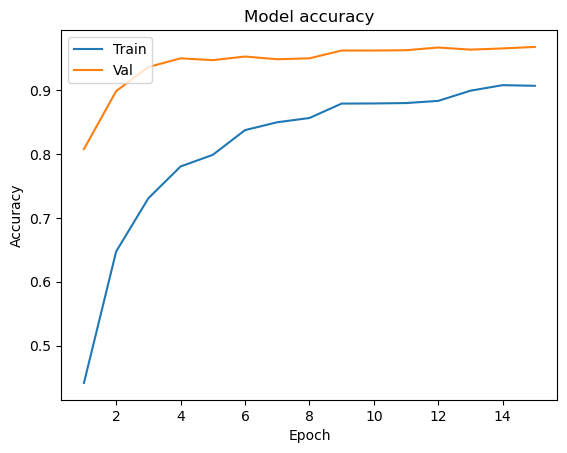

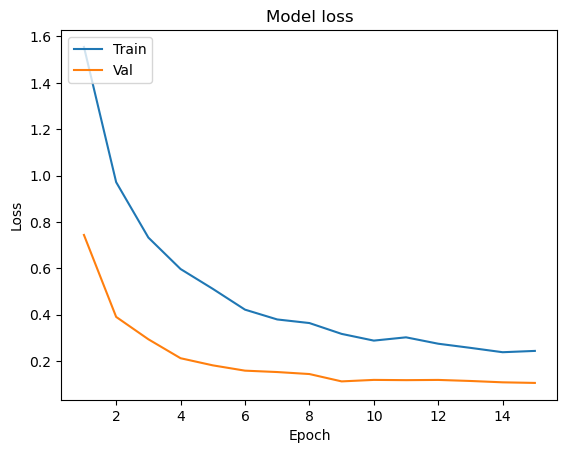

In [44]:
plot_learning(history, 15)

In [39]:
y_pred = np.argmax(model.predict(x_test), axis = 1)

67/67 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


### Confusion Matrix

(<Figure size 700x700 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

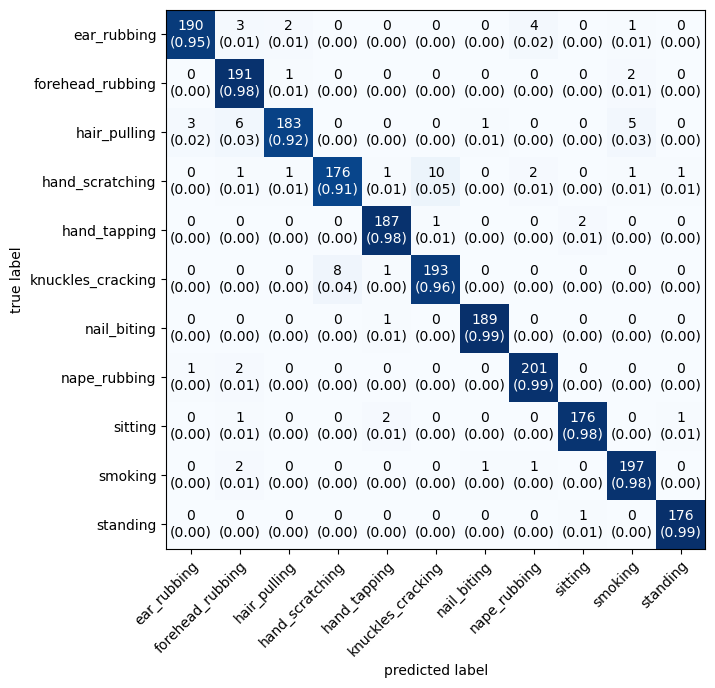

In [40]:
cmat = confusion_matrix(y_test, y_pred)
plot_confusion_matrix(conf_mat=cmat, class_names=label.classes_, show_normed=True, figsize=(7,7))

In [ ]:
#save model

model.save_weights('models/model_all.h5')

In [ ]:
model.save("models/model_all.keras")